# Examen CP2 année scolaire 2020 - 2021

__note__ : il vous est demandé de créer et de rendre un notebook à la fin de l'examen et d'envoyer ce notebook à l'adresse cyril.fonlupt@univ-littoral

__note 2__ : n'oubliez pas de renommer le notebook sous le format NOM-PRENOM

In [42]:
# commencez par importer le module pandas
import pandas as pd

In [43]:
# chargez le fichier concernant un relevé de téléphonie mobile
data = pd.read_csv('téléphone.csv', encoding='ISO-8859-1')
data

,index,date,durée,item,mois,réseau,type
0,0,15/10/14 06:58,34.429,data,2014-11,data,data
1,1,15/10/14 06:58,13.000,call,2014-11,Orange,mobile
2,2,15/10/14 14:46,23.000,call,2014-11,Free,mobile
3,3,15/10/14 14:48,4.000,call,2014-11,SFR,mobile
4,4,15/10/14 17:27,4.000,call,2014-11,SFR,mobile
...,...,...,...,...,...,...,...
825,825,13/03/15 00:38,1.000,sms,2015-03,world,world
826,826,13/03/15 00:39,1.000,sms,2015-03,Orange,mobile
827,827,13/03/15 06:58,34.429,data,2015-03,data,data
828,828,14/03/15 00:13,1.000,sms,2015-03,world,world


Quelques éléments correspondant aux différentes colonnes du fichier :
- la colonne **date** correspond bien évidemment à la date de l'appel
- la colonne **durée** à la durée de l'appel en secondes. Un SMS correspondant à 1s
- la colonne **item** correspond au type de l'appel call (appel classique), SMS et data (données)
- la colonne **mois** le mois de l'appel
- la colonne **réseau** au réseau utilisé
- la colonne **type** au type de l'appel data, mobile, international (world), ...

In [44]:
# décompte du nombre d'opérations
# 830
data.shape[0]

830

In [45]:
# quelle est la durée de l'appel le plus long
dur_max=data[data['durée']==data['durée'].max()]
dur_max['durée'].iloc[0]

10528.0

In [72]:
# combien d'appels (item = call) 388
data['item'].value_counts()[0]

388

In [73]:
# Quelle est la durée des appels téléphoniques


In [74]:
# nombre de valeurs différentes pour le réseau
data['réseau'].value_counts().count()

9

In [75]:
# ou encore
data['réseau'].describe()[1]

9

In [76]:
# le pourcentage d'appels (call) par rapport au total (call, sms, data)

In [77]:
val=data['item'].value_counts()
val

call    388
sms     292
data    150
Name: item, dtype: int64

In [78]:
(val / data['item'].count()) *100

call    46.746988
sms     35.180723
data    18.072289
Name: item, dtype: float64

In [79]:
# combien de mois différents sont décrits
data['mois'].value_counts().count()

5

In [80]:
# en utilisant groupby calculez la durée totale de chaque mois
df1=data.groupby('mois').sum()
df1

,index,durée
mois,,
2014-11,26337,26639.441
2014-12,48362,14641.870
2015-01,100259,18223.299
2015-02,90398,15522.299
2015-03,78679,22750.441


In [81]:
# Quelle est la durée des appels (uniquement call) pour chaque mois
df2=data[data['item']== 'call'].groupby('mois').sum()
df2

,index,durée
mois,,
2014-11,10964,25547.0
2014-12,24725,13561.0
2015-01,43114,17070.0
2015-02,43995,14416.0
2015-03,36362,21727.0


In [82]:
# et pour chaque opérateur
df3=data[data['item']== 'call'].groupby('réseau').sum()
df3

,index,durée
réseau,,
Bouygues,49405,36464.0
Free,20894,7200.0
Orange,25664,14621.0
SFR,29264,13828.0
fixe,22583,18433.0
voicemail,11350,1775.0


In [134]:
# enfin afficher le nombre d'appels, sms et de data pour chaque mois
df4=data.groupby(['mois','item']).count()
df4

index  date  durée  réseau  type
mois    item                                  
2014-11 call    107   107    107     107   107
        data     29    29     29      29    29
        sms      94    94     94      94    94
2014-12 call     79    79     79      79    79
        data     30    30     30      30    30
        sms      48    48     48      48    48
2015-01 call     88    88     88      88    88
        data     31    31     31      31    31
        sms      86    86     86      86    86
2015-02 call     67    67     67      67    67
        data     31    31     31      31    31
        sms      39    39     39      39    39
2015-03 call     47    47     47      47    47
        data     29    29     29      29    29
        sms      25    25     25      25    25

In [136]:
l=[]
for i in range(0,df4.shape[0],3):
    l.append(df4.iloc[i][0])
print(l)

[107, 79, 88, 67, 47]


In [137]:
import seaborn as sns

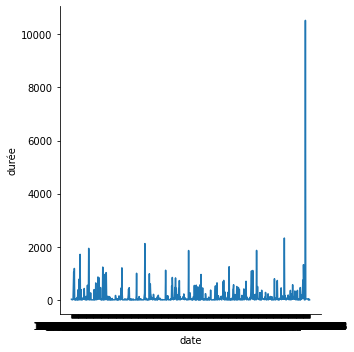

In [138]:
sns.relplot(x = 'date', y = 'durée', data=data, kind = 'line')

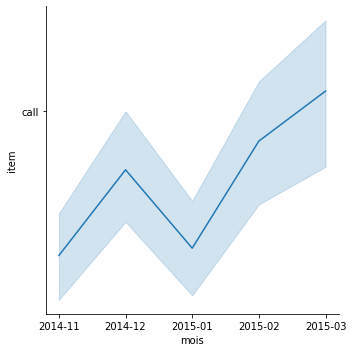

In [162]:
# mettre sous forme graphique
# le nombre d'appels par mois
sns.relplot(x = 'mois', y = 'item', data=data, kind = 'line')


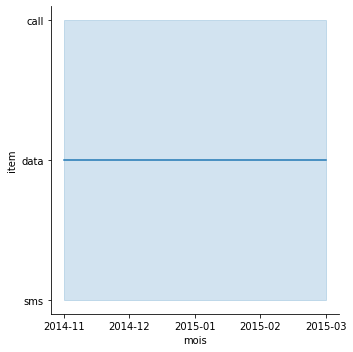

In [172]:
# le nombre d'appels de chaque catégorie (data, call, sms) par mois
df5=data.groupby('mois').count()
sns.relplot(x = 'mois', y = 'item', data=df5, kind = 'line')

In [175]:
df5=data.groupby(['mois','item']).count()
df5

index  date  durée  réseau  type
mois    item                                  
2014-11 call    107   107    107     107   107
        data     29    29     29      29    29
        sms      94    94     94      94    94
2014-12 call     79    79     79      79    79
        data     30    30     30      30    30
        sms      48    48     48      48    48
2015-01 call     88    88     88      88    88
        data     31    31     31      31    31
        sms      86    86     86      86    86
2015-02 call     67    67     67      67    67
        data     31    31     31      31    31
        sms      39    39     39      39    39
2015-03 call     47    47     47      47    47
        data     29    29     29      29    29
        sms      25    25     25      25    25

In [ ]:
# mettre sous forme graphique la durée totale des appels (call) pour chacun des
# mois